# KNN(K-Nearest Neighbor)

[Contents]
1. KNN Low-level implementation  
2. KNN Classification   
   2-1) k에 따른 성과 비교  
   2-2) Scaling 영향 비교

[Data]  
Wine recognition Data set (Multi Class)  
https://scikit-learn.org/stable/datasets/toy_dataset.html#wine-dataset  
shape : 178*13
  
[Task]
1. 최적의 K값 탐색 등 KNN을 활용하여 예측성능 확보하기

활용 데이터
 - Breast Cancer Wisconsin (Diagnostic)
 - https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

[Note]


### KNN Low-level implementation  
 - 관련 Library없이 numpy를 활용한 저수준 구현

In [ ]:
import numpy as np
from collections import Counter

class KNN:
    def __init__(self, k=3):
        self.k = k

    def fit(self, X, y):
        self.X_train = np.array(X)
        self.y_train = np.array(y)

    def predict(self, X):
        preds = [self._predict_one(x) for x in X]
        return np.array(preds)

    def _predict_one(self, x):
        # 거리 계산 (유클리드 거리)
        distances = np.sqrt(np.sum((self.X_train - x) ** 2, axis=1))

        # k개의 최근접 이웃 선택
        k_indices = distances.argsort()[:self.k]
        k_neighbor_labels = self.y_train[k_indices]

        # 다수결 투표
        most_common = Counter(k_neighbor_labels).most_common(1)
        return most_common[0][0]

# 예시 데이터 (이진 분류)
X_train = [[1,2],[2,3],[3,3],[6,7],[7,8],[8,8]]
y_train = [0,0,0,1,1,1]

knn = KNN(k=3)
knn.fit(X_train, y_train)

X_test = [[2,2],[7,7],[3,7]]
print("KNN Inference:", knn.predict(X_test))

KNN Inference: [0 1 0]


### KNN Classification  

- KNN은 거리 기반 알고리즘이므로 특성 스케일링이 중요  
- K값이 너무 작으면 과적합, 너무 크면 과소적합 경향  
- 홀수 K값 사용권고, 동점 상황 방지  

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [3]:
# 1. 데이터 로드
wine = load_wine()
X, y = wine.data, wine.target

df = pd.DataFrame(X, columns=wine.feature_names)
df['target'] = y

print(f"Data Shape: {df.shape}")
print(f"Info: {df.info()}")
print(f"Samples: {df.head(5)}")

Data Shape: (178, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null

In [4]:
# 2. 데이터 탐색
print("\n결측치 확인:")
print(df.isnull().sum())

print("\n타겟 변수 분포:")
print(f"Target Class Name: {wine.target_names}")
target_counts = df['target'].value_counts()
print(target_counts)
print(f"비율: {target_counts / len(df) * 100}")



결측치 확인:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64

타겟 변수 분포:
Target Class Name: ['class_0' 'class_1' 'class_2']
target
1    71
0    59
2    48
Name: count, dtype: int64
비율: target
1    39.887640
0    33.146067
2    26.966292
Name: count, dtype: float64


In [5]:
# 3. 모델링
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3-1 K값 비교 (스케일링 전)
k_values = [1, 3, 5, 9, 11]
accuracies_no_scaling = []

print("\n=== 스케일링 전 결과 ===")
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    accuracies_no_scaling.append(accuracy)
    print(f"K={k}: Accuracy = {accuracy:.4f}")

# 3-2 스케일링 적용
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3-3 K값 비교 (스케일링 후)
accuracies_with_scaling = []

print("\n=== 스케일링 후 결과 ===")
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)
    accuracies_with_scaling.append(accuracy)
    print(f"K={k}: Accuracy = {accuracy:.4f}")

# 3-4 최적 모델 선택 및 상세 평가
best_k_idx = np.argmax(accuracies_with_scaling)
best_k = k_values[best_k_idx]
print(f"\n최적 K값: {best_k} (Accuracy: {accuracies_with_scaling[best_k_idx]:.4f})")

# 3-5 최적 모델로 예측
best_knn = KNeighborsClassifier(
    n_neighbors=best_k
   #  ,metric     # 'minkowski'(Default), 'euclidean', 'manhattan', 'cosine', 'mahalanobis'..
   #  ,p          # Minkowski 거리의 차수, p=1: manhattan, p=2: euclidean(Default)
   #  ,weights    # 'uniform': 모든 이웃이 동일한 가중치(Default), 'distance': 가까운 이웃에 더 큰 가중치
    )
best_knn.fit(X_train_scaled, y_train)
y_pred_best = best_knn.predict(X_test_scaled)


=== 스케일링 전 결과 ===
K=1: Accuracy = 0.7778
K=3: Accuracy = 0.7500
K=5: Accuracy = 0.8056
K=9: Accuracy = 0.8056
K=11: Accuracy = 0.8056

=== 스케일링 후 결과 ===
K=1: Accuracy = 0.9722
K=3: Accuracy = 0.9722
K=5: Accuracy = 0.9722
K=9: Accuracy = 1.0000
K=11: Accuracy = 1.0000

최적 K값: 9 (Accuracy: 1.0000)


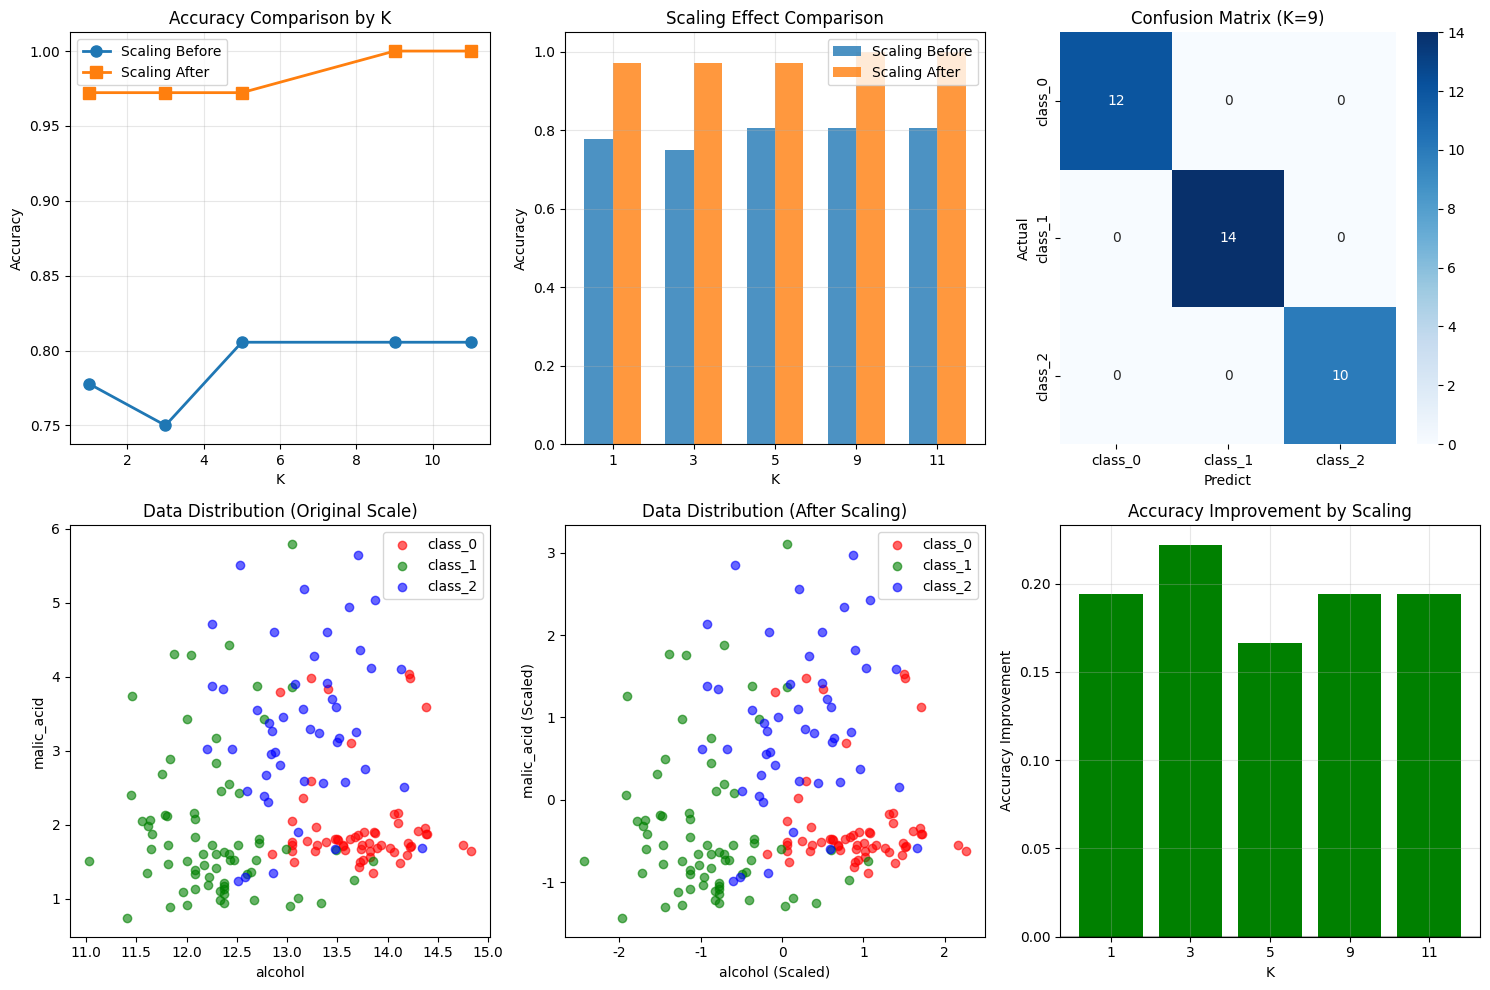


=== 최종 결과 요약 ===
최적 K값: 9
최종 정확도: 1.0000
스케일링 효과: 0.1944

=== 상세 분류 보고서 ===
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

이 데이터셋에서는 스케일링 후 평균 0.1944 정확도 향상


In [ ]:
# 4. 성과분석
plt.figure(figsize=(15, 10))

# 4-1. K값에 따른 정확도 비교
plt.subplot(2, 3, 1)
plt.plot(k_values, accuracies_no_scaling, 'o-', label='Scaling Before', linewidth=2, markersize=8)
plt.plot(k_values, accuracies_with_scaling, 's-', label='Scaling After', linewidth=2, markersize=8)
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.title('Accuracy Comparison by K')
plt.legend()
plt.grid(True, alpha=0.3)

# 4-2. 스케일링 효과 막대 그래프
plt.subplot(2, 3, 2)
x_pos = np.arange(len(k_values))
width = 0.35
plt.bar(x_pos - width/2, accuracies_no_scaling, width, label='Scaling Before', alpha=0.8)
plt.bar(x_pos + width/2, accuracies_with_scaling, width, label='Scaling After', alpha=0.8)
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.title('Scaling Effect Comparison')
plt.xticks(x_pos, k_values)
plt.legend()
plt.grid(True, alpha=0.3)

# 4-3. 혼동 행렬
plt.subplot(2, 3, 3)
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=wine.target_names, yticklabels=wine.target_names)
plt.title(f'Confusion Matrix (K={best_k})')
plt.ylabel('Actual')
plt.xlabel('Predict')

# 4-4. 특성 분포 (처음 2개 특성만)
plt.subplot(2, 3, 4)
colors = ['red', 'green', 'blue']
for i, target_name in enumerate(wine.target_names):
    mask = y == i
    plt.scatter(X[mask, 0], X[mask, 1], c=colors[i], label=target_name, alpha=0.6)
plt.xlabel(wine.feature_names[0])
plt.ylabel(wine.feature_names[1])
plt.title('Data Distribution (Original Scale)')
plt.legend()

# 4-5. 스케일링된 특성 분포
plt.subplot(2, 3, 5)
X_all_scaled = scaler.fit_transform(X)
for i, target_name in enumerate(wine.target_names):
    mask = y == i
    plt.scatter(X_all_scaled[mask, 0], X_all_scaled[mask, 1], c=colors[i], label=target_name, alpha=0.6)
plt.xlabel(f'{wine.feature_names[0]} (Scaled)')
plt.ylabel(f'{wine.feature_names[1]} (Scaled)')
plt.title('Data Distribution (After Scaling)')
plt.legend()

# 4-6. 정확도 향상 비교
plt.subplot(2, 3, 6)
improvement = np.array(accuracies_with_scaling) - np.array(accuracies_no_scaling)
plt.bar(range(len(k_values)), improvement, color=['green' if x > 0 else 'red' for x in improvement])
plt.xlabel('K')
plt.ylabel('Accuracy Improvement')
plt.title('Accuracy Improvement by Scaling')
plt.xticks(range(len(k_values)), k_values)
plt.axhline(y=0, color='black', linestyle='-', alpha=0.3)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 5. 최종 결과 요약
print(f"\n=== 최종 결과 요약 ===")
print(f"최적 K값: {best_k}")
print(f"최종 정확도: {accuracies_with_scaling[best_k_idx]:.4f}")
print(f"스케일링 효과: {accuracies_with_scaling[best_k_idx] - accuracies_no_scaling[best_k_idx]:.4f}")

print(f"\n=== 상세 분류 보고서 ===")
print(classification_report(y_test, y_pred_best, target_names=wine.target_names))

print(f"이 데이터셋에서는 스케일링 후 평균 {np.mean(improvement):.4f} 정확도 향상")

### Task: KNN Classification, 최적의 k 탐색으로 변별력 확보하기  


In [6]:
!pip install ucimlrepo

In [1]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder
from ucimlrepo import fetch_ucirepo

# 1. UCI에서 데이터 불러오기
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17)
X = breast_cancer_wisconsin_diagnostic.data.features
y = breast_cancer_wisconsin_diagnostic.data.targets

# 2. 라벨 인코딩 (M=1, B=0)
le = LabelEncoder()
y = le.fit_transform(y)

# 3. Train/Test 분리
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


/Users/psm/workspace/skala-machine_running/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
